# Getting started with `discopt.speciation`

`discopt.speciation` computes chemical equilibrium in water: which dissolved species form, how much of each, and which solids precipitate. You declare species and reactions, each with an equilibrium constant $\log_{10} K$. The equations are solved with the NLP solvers of [discopt](https://github.com/jkitchin/discopt). The package reads PHREEQC databases (Parkhurst and Appelo 2013, [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)), but in this notebook every constant is typed in by hand.

**What you will learn.**
- How to declare species, reactions and solids: operator form, string form, and YAML/dict specs.
- How to read a `Result`: phases present, saturation indices, molalities, residuals.
- How to use activity models, fixed pH, metastable polymorphs, and the three solution methods.

**Prerequisites.** Basic aqueous chemistry. No earlier notebook is needed.

**The equilibrium conditions.** The plugin finds the state that satisfies:

- **mass action** for every reaction: $\sum_i \nu_i \log_{10} a_i = \log_{10} K$. Here $\nu_i$ is the stoichiometric coefficient (positive for products) and $a_i=\gamma_i m_i$ is the *activity*: molality $m_i$ (mol/kg water) times an activity coefficient $\gamma_i$.
- **conservation** of every quantity the reactions cannot change, such as element totals. These are computed from the network, not typed in.
- **complementarity** for every candidate solid $k$: $n_k \ge 0$, $\mathrm{SI}_k \le 0$, and $n_k\,\mathrm{SI}_k = 0$. The saturation index is $\mathrm{SI}_k=\log_{10}(Q_k/K_k)$, where $Q_k$ is the activity product. A solid is either present and saturated ($\mathrm{SI}=0$), or absent and undersaturated ($\mathrm{SI}<0$).

The third condition is the one that is easy to get wrong. Without it, the answer depends on how reactions are written and on which phases are listed as candidates. This is the problem with the SI²-minimization approach of Laliwala et al. (2025, [doi:10.69997/sct.132742](https://doi.org/10.69997/sct.132742)). [`02-validation.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/02-validation.ipynb) re-solves their cases.

**The notebooks.**

| notebook | topic |
|---|---|
| **01-getting-started** | this notebook |
| 02-validation | the Laliwala et al. cases and evidence of correctness |
| 03-databases-and-your-own-data | PHREEQC databases, adding and overriding data |
| 04-fitting-thermodynamic-data | fitting constants to measurements |
| 05-diagrams | speciation, Pourbaix and Ellingham diagrams |
| 06-rare-earths-and-thorium | a larger worked application |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import yaml

from discopt.speciation import System, solve_spec

## Declaring a system: gypsum solubility

**Goal.** Build the smallest useful system: calcium, sulfate, their neutral ion pair, and gypsum (CaSO₄·2H₂O).

- Species are created on a `System`. Charges come from the name suffix (`"SO4-2"` → −2) unless given explicitly.
- In a reaction, `+` joins species, `2 * X` sets a stoichiometric coefficient, and `>>` separates reactants from products.
- `logK` is base 10, at 25 °C, for the reaction as written (products over reactants).
- Solids have unit activity. Every solid needs exactly one reaction that links it to aqueous species, i.e. its solubility product $K_{sp}$.
- The default activity model is ideal ($\gamma_i = 1$).

In [2]:
s = System("gypsum")
Ca, SO4, CaSO4 = s.aqueous("Ca+2"), s.aqueous("SO4-2"), s.aqueous("CaSO4")
gypsum = s.solid("Gypsum")

s.reaction(Ca + SO4 >> CaSO4, logK=2.36)      # aqueous ion pair
s.reaction(gypsum >> Ca + SO4, logK=-4.61)    # solubility product
s

System('gypsum', 3 aqueous, 1 solid, 2 reactions)

`equilibrate` takes input amounts in mol per kg of water (molal units). Only the conserved totals (here total Ca and total SO₄) matter. So adding 0.0324 mol Ca²⁺ and 0.025 mol SO₄²⁻ is the same as adding 0.025 mol CaSO₄ plus 0.0074 mol Ca²⁺.

In [3]:
res = s.equilibrate({Ca: 0.0324, SO4: 0.025})
print(res.summary())

converged=True method=complementarity I=0.02473 charge_imbalance=0.0148 G/RT=-0.13328574
aqueous                   molality     log10 a
Ca+2                  9.883615e-03     -2.0051
SO4-2                 2.483615e-03     -2.6049
CaSO4                 5.623413e-03     -2.2500
solid                       amount          SI
Gypsum                1.689297e-02     -0.0000
residuals: balance=1.4e-16, mass_action=0.0e+00, complementarity=0.0e+00


**Result.** 0.0169 mol/kg gypsum precipitates, and its SI is exactly zero. What stays dissolved is mostly free Ca²⁺ (0.0099 mol/kg) and the CaSO₄ ion pair (0.0056 mol/kg). The last line shows the residuals of the three conditions, which are all at machine precision. `I` is the ionic strength, $I=\tfrac12\sum_i m_i z_i^2$.

**Charge.** `charge_imbalance` is 0.0148 = 2(0.0324 − 0.025), because the excess Ca²⁺ has no counter-ion. Electroneutrality is not imposed as a constraint: it follows from whatever you add. Add a counter-ion such as Cl⁻, or pass `charge_balance=`, for a neutral solution.

**Reading a `Result`.**
- `res["Ca+2"]` gives a molality, or a solid amount, by name.
- `res.present` lists the solids at equilibrium.
- `res.SI` gives $\log_{10}(Q/K)$ for every candidate solid.
- `res.pH` is `None` here, because this system has no H⁺.

**Undersaturated case.** The next cell writes the same system with string reactions, which are equivalent to the operator form. It then adds less material, so gypsum should be absent with a negative SI.

In [4]:
s2 = System("gypsum (string form)")
for name in ["Ca+2", "SO4-2", "CaSO4"]:
    s2.aqueous(name)
s2.solid("Gypsum")
s2.reaction("Ca+2 + SO4-2 = CaSO4", logK=2.36)
s2.reaction("Gypsum = Ca+2 + SO4-2", logK=-4.61)

dilute = s2.equilibrate({"Ca+2": 1e-3, "SO4-2": 1e-3})
print("present:", dilute.present, " SI:", dilute.SI, " converged:", dilute.converged)

present: []  SI: {'Gypsum': -1.5426697761417643}  converged: True


## Solubility curve and activity coefficients

**Goal.** See how solubility depends on the activity model. We sweep the amount of CaSO₄ added from 10⁻³ to 10⁻¹ mol/kg. Dissolved calcium should rise until the solution saturates, then stay flat as the extra material precipitates.

Real ions interact, so their activity is lower than their molality ($\gamma_i<1$). The Davies equation (Davies 1938, [doi:10.1039/JR9380002093](https://doi.org/10.1039/JR9380002093)) estimates $\gamma_i$ from the charge $z_i$ and the ionic strength $I$ alone:
$\log_{10}\gamma_i=-A z_i^2\left(\frac{\sqrt I}{1+\sqrt I}-0.3I\right)$, with $A\approx0.51$ at 25 °C. It is a reasonable model up to $I$ of a few tenths of a mol/kg. Other models are covered in [`docs/activity-models.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/activity-models.md).

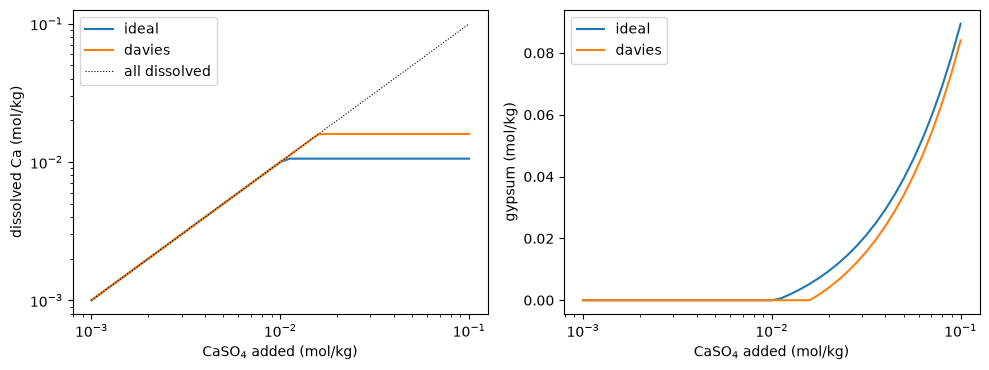

In [5]:
added = np.logspace(-3, -1, 41)
curves = {}
for model in ["ideal", "davies"]:
    dissolved, solid = [], []
    for c in added:
        r = s.equilibrate({Ca: c, SO4: c}, activity=model)
        assert r.converged
        dissolved.append(r["Ca+2"] + r["CaSO4"])
        solid.append(r["Gypsum"])
    curves[model] = (np.array(dissolved), np.array(solid))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for model, (d, n) in curves.items():
    ax[0].loglog(added, d, label=model)
    ax[1].semilogx(added, n, label=model)
ax[0].loglog(added, added, "k:", lw=0.8, label="all dissolved")
ax[0].set(xlabel="CaSO$_4$ added (mol/kg)", ylabel="dissolved Ca (mol/kg)")
ax[1].set(xlabel="CaSO$_4$ added (mol/kg)", ylabel="gypsum (mol/kg)")
ax[0].legend()
ax[1].legend()
plt.tight_layout()

**Result.** Left panel: dissolved Ca follows the "all dissolved" line until saturation. It then plateaus at 0.0106 mol/kg with ideal activities and 0.0160 mol/kg with Davies, about 50 % higher. Right panel: gypsum is zero before saturation and grows linearly after it; the log x-axis makes that line look curved. At the plateau, $I$ is 0.020 (ideal) and 0.041 (Davies). Davies gives $\gamma_{\mathrm{Ca^{2+}}}=0.48$ there, so more ions must dissolve to reach $K_{sp}$. The sharp corner is where complementarity switches gypsum from absent to present.

**Temperature.** `equilibrate(..., T=...)` takes kelvin. `logK` values are for 25 °C and change with $T$ only if a reaction has `dH`, `dCp` or `analytic=` data (see [`docs/custom-data.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/custom-data.md)). The gypsum reactions have none, so at 50 °C only the Davies $A$ parameter changes: dissolved Ca moves from 0.01596 to 0.01649 mol/kg.

In [6]:
for T in [298.15, 323.15]:
    r = s.equilibrate({Ca: 0.1, SO4: 0.1}, T=T, activity="davies")
    print(f"T = {T} K   dissolved Ca = {r['Ca+2'] + r['CaSO4']:.5f} mol/kg")

T = 298.15 K   dissolved Ca = 0.01596 mol/kg
T = 323.15 K   dissolved Ca = 0.01649 mol/kg


## Fixed activities: iron(III) solubility versus pH

**Goal.** Compute Fe(III) solubility from pH 1 to 13, and see how complementarity picks between two solids of the same composition.

**Fixed activities.** A species can be held at a fixed $\log_{10}$ activity, which models an open reservoir. `pH=7` is shorthand for `fixed={"H+": -7}`. The amount of H⁺ is then not conserved: acid or base is exchanged as needed.

**The system.** Fe(III) hydrolysis species and two iron oxyhydroxides, goethite and ferrihydrite. The constants are from the minteq.v4 database (Allison et al. 1991, [OSTI 5673069](https://www.osti.gov/biblio/5673069)). Water is left out of these reactions, which is the same as giving it activity 1.

**Polymorphs.** The two solids have the same stoichiometry, but goethite's $\log_{10} K$ is 2.7 units lower (0.491 vs 3.191), so it is more stable. When both are candidates, only goethite may form, whatever order they are declared in. Ferrihydrite is *metastable*: it can persist in practice but is not the equilibrium phase. To compute its higher solubility, either leave goethite out of the system, as done below, or pass `equilibrate(..., suppress=["Goethite"])`.

Ferrihydrite + Goethite -> phases found: ['Goethite']


Ferrihydrite -> phases found: ['Ferrihydrite']


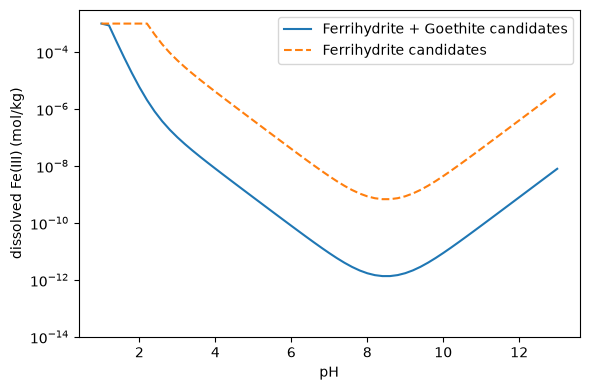

In [7]:
def iron_system(solids):
    fe = System("iron(III)")
    for name in ["H+", "Fe+3", "FeOH+2", "Fe(OH)2+", "Fe(OH)3", "Fe(OH)4-", "Fe2(OH)2+4", "Fe3(OH)4+5"]:
        fe.aqueous(name)
    fe.reaction("Fe+3 = FeOH+2 + H+", logK=-2.187)
    fe.reaction("Fe+3 = Fe(OH)2+ + 2 H+", logK=-4.594)
    fe.reaction("Fe+3 = Fe(OH)3 + 3 H+", logK=-12.56)
    fe.reaction("Fe+3 = Fe(OH)4- + 4 H+", logK=-21.588)
    fe.reaction("2 Fe+3 = Fe2(OH)2+4 + 2 H+", logK=-2.854)
    fe.reaction("3 Fe+3 = Fe3(OH)4+5 + 4 H+", logK=-6.288)
    logK = {"Ferrihydrite": 3.191, "Goethite": 0.491}
    for name in solids:
        fe.solid(name)
        fe.reaction(f"{name} + 3 H+ = Fe+3", logK=logK[name])
    return fe

# Fe atoms per aqueous species, to sum up total dissolved Fe(III)
IRON = {"Fe+3": 1, "FeOH+2": 1, "Fe(OH)2+": 1, "Fe(OH)3": 1, "Fe(OH)4-": 1, "Fe2(OH)2+4": 2, "Fe3(OH)4+5": 3}
pH = np.linspace(1, 13, 61)
fig, ax = plt.subplots(figsize=(6, 4))
for solids, style in [(["Ferrihydrite", "Goethite"], "-"), (["Ferrihydrite"], "--")]:
    system = iron_system(solids)
    dissolved, phase = [], []
    for p in pH:
        r = system.equilibrate({"Fe+3": 1e-3}, pH=p)
        assert r.converged, p
        dissolved.append(sum(c * r[k] for k, c in IRON.items()))
        phase.append(r.present)
    ax.semilogy(pH, dissolved, style, label=" + ".join(solids) + " candidates")
    print(" + ".join(solids), "-> phases found:", sorted({x for ph in phase for x in ph}))
ax.set(xlabel="pH", ylabel="dissolved Fe(III) (mol/kg)", ylim=(1e-14, 3e-3))
ax.legend()
plt.tight_layout()

**Result.** The printout confirms that ferrihydrite never forms when goethite is a candidate.
- **Low pH.** All 10⁻³ mol/kg Fe stays dissolved at the lowest pH. Goethite appears from about pH 1.2; ferrihydrite alone does not saturate until about pH 2.2.
- **Minimum.** Both curves reach a minimum near pH 8.5: about 1.4×10⁻¹² mol/kg over goethite and 6.8×10⁻¹⁰ over ferrihydrite. The ratio, about 500, is exactly $10^{2.7}$, the difference in $\log_{10} K$.
- **High pH.** Solubility rises again as Fe(OH)₄⁻ takes over.

At every pH where goethite is present, ferrihydrite has SI = −2.7.

## Three solution methods

**Goal.** Check one answer three independent ways. `method=` chooses how the phase assemblage, i.e. the set of solids present, is found. All three should give the same state, and after the solve every method checks the equilibrium conditions to tight tolerance.

| method | idea | notes |
|---|---|---|
| `"complementarity"` (default) | log-molality mass action plus a smoothed Fischer–Burmeister equation per solid (Fischer 1992, [doi:10.1080/02331939208843795](https://doi.org/10.1080/02331939208843795)), driven through an ε-homotopy (Kanzow 1996, [doi:10.1137/S0895479894273134](https://doi.org/10.1137/S0895479894273134)) | any activity model |
| `"gibbs"` | minimize $G/RT$ subject to conservation (Smith and Missen 1982) | convex for ideal activities, so a local solve is global; needs an activity model with an excess Gibbs energy (ideal, Davies, SIT, Pitzer; not Truesdell–Jones or B-dot) |
| `"enumerate"` | solve for every subset of present solids and keep the one that satisfies complementarity | proves uniqueness; cost grows as $2^{\#\text{solids}}$ (limit 12 phases) |

Leal et al. (2017, [doi:10.1515/pac-2016-1107](https://doi.org/10.1515/pac-2016-1107)) review mass-action and Gibbs-minimization methods. The cell below solves the first gypsum problem with each method.

In [8]:
import time
for method in ["complementarity", "gibbs", "enumerate"]:
    t0 = time.perf_counter()
    r = s.equilibrate({Ca: 0.0324, SO4: 0.025}, method=method)
    print(f"{method:16s} gypsum = {r['Gypsum']:.12e}   SI = {r.SI['Gypsum']:+.1e}   "
          f"converged = {r.converged}   ({time.perf_counter() - t0:.2f} s)")

complementarity  gypsum = 1.689297217757e-02   SI = -0.0e+00   converged = True   (0.03 s)
gibbs            gypsum = 1.689297217757e-02   SI = -0.0e+00   converged = True   (0.02 s)
enumerate        gypsum = 1.689297217757e-02   SI = -0.0e+00   converged = True   (0.02 s)


**Result.** All three methods give the same gypsum amount to 12 significant figures, with SI zero to rounding (≤ 10⁻¹⁵). Run times are hundredths of a second and vary between runs. The `02-validation` notebook uses this agreement as one of its lines of evidence.

## Declarative specs (YAML / JSON / dict)

**Goal.** Write the same problem as data instead of code. The schema is strict, so a misspelled key raises an error instead of being silently ignored. `solve_spec` accepts YAML, JSON or a dict and returns a JSON-serializable dict, which suits scripts and LLM agents. Each species is listed with its `phase` (aqueous is the default) and each reaction as an `equation` string. The same schema is documented in [`docs/custom-data.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/custom-data.md).

In [9]:
spec = '''
name: gypsum
activity: davies
species:
  - {name: Ca+2}
  - {name: SO4-2}
  - {name: CaSO4}
  - {name: Gypsum, phase: solid}
reactions:
  - {equation: "Ca+2 + SO4-2 = CaSO4", logK: 2.36}
  - {equation: "Gypsum = Ca+2 + SO4-2", logK: -4.61}
problem:
  amounts: {Ca+2: 0.0324, SO4-2: 0.025}
'''
out = solve_spec(spec)
print({k: out[k] for k in ["converged", "present", "solids", "SI", "ionic_strength"]})

{'converged': True, 'present': ['Gypsum'], 'solids': {'Gypsum': 0.01188185400576505}, 'SI': {'Gypsum': 8.881784197001252e-16}, 'ionic_strength': 0.044778930969325864}


**Result.** This spec sets `activity: davies`, so it matches the Davies curve rather than the first (ideal) calculation. Less gypsum precipitates (0.0119 vs 0.0169 mol/kg) and the ionic strength is higher (0.045 vs 0.025).

`System.to_spec()` goes the other way: it exports a system built in code. The export writes out the defaults: `temperature` in K, `activity: ideal`, charges, and each reaction as a `stoich` dict (negative for reactants).

In [10]:
# any System can be exported to the same schema
print(yaml.safe_dump(s.to_spec(), sort_keys=False))

name: gypsum
temperature: 298.15
activity: ideal
species:
- name: Ca+2
  phase: aqueous
  charge: 2.0
- name: SO4-2
  phase: aqueous
  charge: -2.0
- name: CaSO4
  phase: aqueous
  charge: 0.0
- name: Gypsum
  phase: solid
reactions:
- stoich:
    Ca+2: -1.0
    SO4-2: -1.0
    CaSO4: 1.0
  logK: 2.36
- stoich:
    Gypsum: -1.0
    Ca+2: 1.0
    SO4-2: 1.0
  logK: -4.61



## Summary

- A `System` holds aqueous species, solids and reactions with `logK`. Build it with operators (`>>`), with equation strings, or from a YAML/dict spec.
- `equilibrate` enforces mass action, conservation and complementarity. Solids come out either present with SI = 0 or absent with SI < 0.
- Complementarity picks the stable polymorph automatically. Use `suppress=` or leave the stable phase out to get metastable equilibria.
- The activity model matters even at moderate ionic strength: Davies raised gypsum solubility by about 50 % here.
- The three methods agree, which is a built-in consistency check.

## Next steps

- [`02-validation.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/02-validation.ipynb): why complementarity is needed, with the Laliwala et al. (2025) cases checked against PHREEQC.
- [`03-databases-and-your-own-data.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/03-databases-and-your-own-data.ipynb): load [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) and other databases instead of typing constants.
- Docs: [`docs/concepts.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/concepts.md) (conditions, methods, units), [`docs/activity-models.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/activity-models.md), [`docs/custom-data.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/custom-data.md).

## References

- Allison, J.D., Brown, D.S., and Novo-Gradac, K.J. (1991). *MINTEQA2/PRODEFA2, a geochemical assessment model for environmental systems: version 3.0 user's manual.* EPA/600/3-91/021. <https://www.osti.gov/biblio/5673069>
- Davies, C.W. (1938). The extent of dissociation of salts in water. Part VIII. *Journal of the Chemical Society*, 2093. <https://doi.org/10.1039/JR9380002093>
- Fischer, A. (1992). A special Newton-type optimization method. *Optimization* 24, 269–284. <https://doi.org/10.1080/02331939208843795>
- Kanzow, C. (1996). Some noninterior continuation methods for linear complementarity problems. *SIAM Journal on Matrix Analysis and Applications* 17, 851–868. <https://doi.org/10.1137/S0895479894273134>
- Kitchin, J. *discopt*. <https://github.com/jkitchin/discopt>
- Laliwala, C.A., et al. (2025). An optimization-based law of mass action precipitation/dissolution model. *Systems and Control Transactions* 4, 2140–2145. <https://doi.org/10.69997/sct.132742>
- Leal, A.M.M., Kulik, D.A., Smith, W.R., and Saar, M.O. (2017). An overview of computational methods for chemical equilibrium and kinetic calculations for geochemical and reactive transport modeling. *Pure and Applied Chemistry* 89, 597–643. <https://doi.org/10.1515/pac-2016-1107>
- Parkhurst, D.L., and Appelo, C.A.J. (2013). *Description of input and examples for PHREEQC version 3.* USGS Techniques and Methods 6-A43. <https://doi.org/10.3133/tm6A43>
- Smith, W.R., and Missen, R.W. (1982). *Chemical Reaction Equilibrium Analysis: Theory and Algorithms.* Wiley, New York.

The full bibliography is in [`docs/references.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/references.md).